In [43]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt

In [44]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

torch.Size([1, 28, 28]) 3


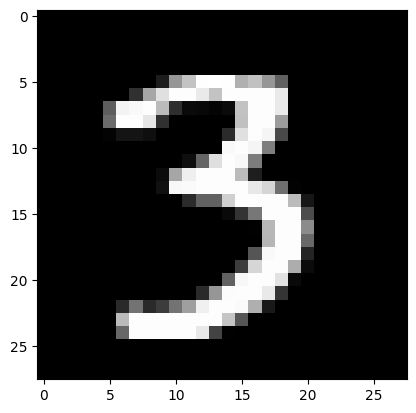

In [45]:
img, label = train_dataset[10000]
print(img.shape, label)
plt.imshow(img.squeeze(), cmap='gray')
plt.show()

In [46]:
class mnist_cnn(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
    self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
    self.fc1 = nn.Linear(64*7*7,64)
    self.fc2 = nn.Linear(64,10)
    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(0.25)
  def forward(self,x):
    x = self.pool(self.relu(self.conv1(x)))
    x = self.pool(self.relu(self.conv2(x)))
    x = self.dropout(x)
    x = x.view(-1,64*7*7)
    x = self.fc1(x)
    x = self.relu(x)
    x = self.fc2(x)
    return x

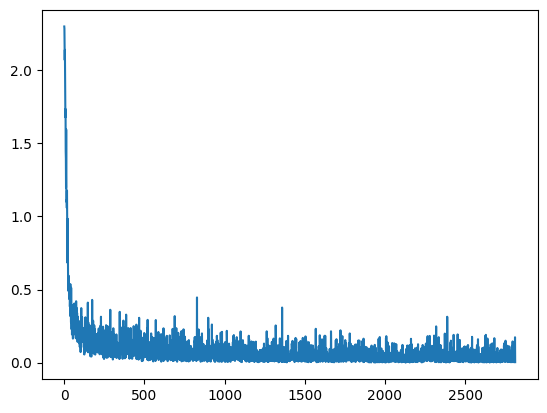

In [42]:
model = mnist_cnn().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
erro = []

for i in range(3):
  model.train()
  for img, label in train_loader:
    img, label = img.to(device), label.to(device)
    output = model(img)
    loss = criterion(output, label)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    erro.append(loss.item())
plt.plot(range(len(erro)), erro)
plt.show()

In [47]:
with torch.no_grad():
  model.eval()
  acc = 0
  for img, label in test_loader:
    img, label = img.to(device), label.to(device)
    output = model.forward(img)
    pred = torch.argmax(output, dim=1)
    acc += accuracy_score(label.cpu().numpy(), pred.cpu().numpy())
print(acc/len(test_loader))

0.9925373134328358


In [48]:
params_with_grad = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Quantidade de parametros: {params_with_grad}')

Quantidade de parametros: 220234


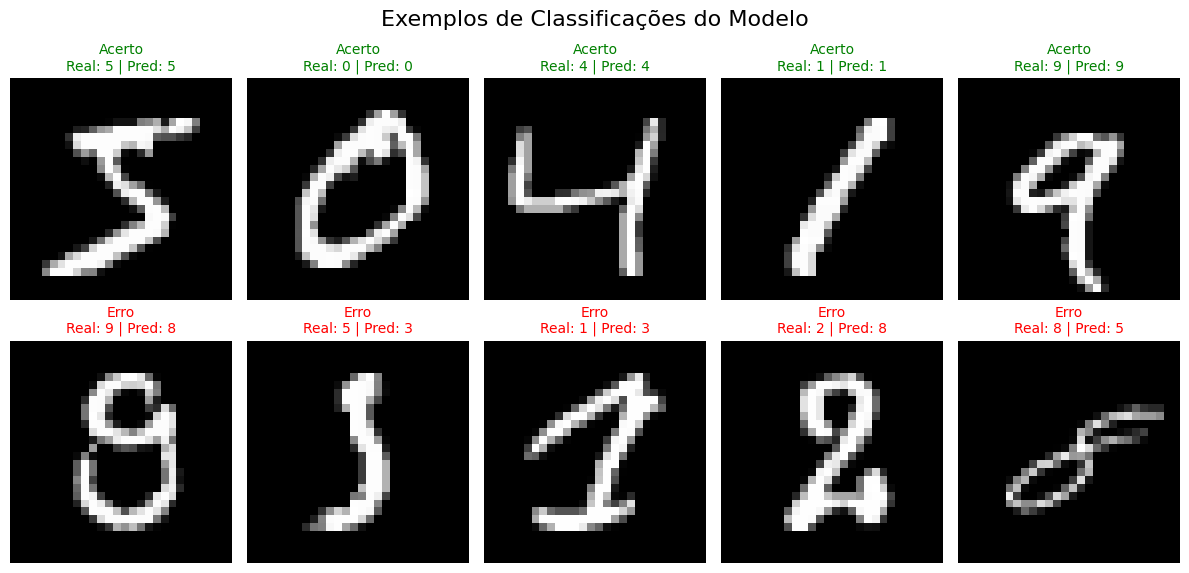

In [49]:
import random

model.eval()
correct_examples = []
incorrect_examples = []

with torch.no_grad():
    for img, label in test_loader:
        img_dev, label_dev = img.to(device), label.to(device)
        output = model(img_dev)
        pred = torch.argmax(output, dim=1).cpu()

        for i in range(len(label)):
            true_lbl = label[i].item()
            pred_lbl = pred[i].item()
            img_np = img[i].squeeze().numpy()

            if true_lbl == pred_lbl:
                if len(correct_examples) < 5:
                    correct_examples.append((img_np, true_lbl, pred_lbl))
            else:
                if len(incorrect_examples) < 5:
                    incorrect_examples.append((img_np, true_lbl, pred_lbl))

            if len(correct_examples) >= 5 and len(incorrect_examples) >= 5:
                break
        if len(correct_examples) >= 5 and len(incorrect_examples) >= 5:
            break

# Plotting the results
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
fig.suptitle('Exemplos de Classificações do Modelo', fontsize=16)

# Plot Correct Examples
for idx, (img, true_lbl, pred_lbl) in enumerate(correct_examples):
    ax = axes[0, idx]
    ax.imshow(img, cmap='gray')
    ax.set_title(f'Acerto\nReal: {true_lbl} | Pred: {pred_lbl}', color='green', fontsize=10)
    ax.axis('off')

# Plot Incorrect Examples
for idx, (img, true_lbl, pred_lbl) in enumerate(incorrect_examples):
    ax = axes[1, idx]
    ax.imshow(img, cmap='gray')
    ax.set_title(f'Erro\nReal: {true_lbl} | Pred: {pred_lbl}', color='red', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

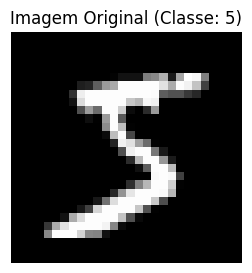

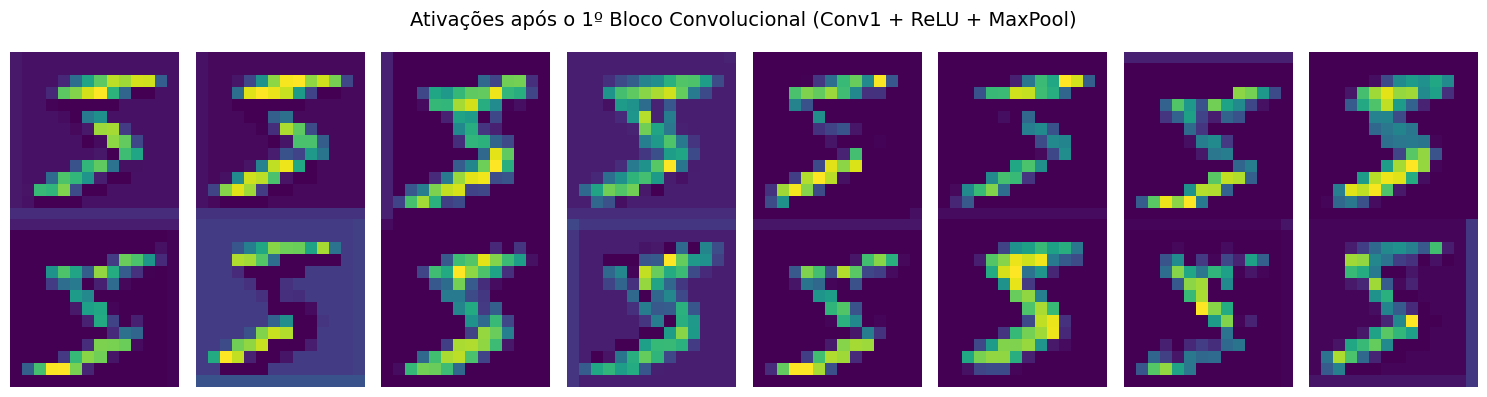

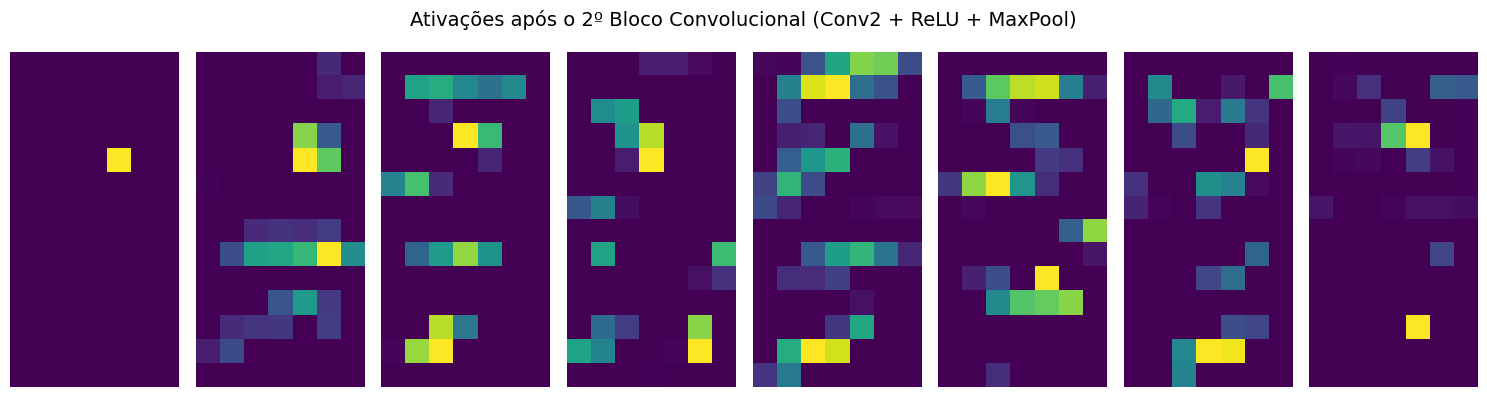

In [50]:
model.eval()

# Selecionar uma única imagem para visualização
img, label = test_dataset[0]
img_tensor = img.unsqueeze(0).to(device)  # Adiciona dimensão de lote (batch dimension)

# Obter as ativações após o primeiro bloco convolucional (conv1 -> relu -> pool)
with torch.no_grad():
    first_block_output = model.pool(model.relu(model.conv1(img_tensor)))
    # Obter as ativações após o segundo bloco convolucional (first_block -> conv2 -> relu -> pool)
    second_block_output = model.pool(model.relu(model.conv2(first_block_output)))

# Converter tensores para numpy para plotagem
first_block_features = first_block_output.squeeze(0).cpu().numpy()
second_block_features = second_block_output.squeeze(0).cpu().numpy()

# Exibir a imagem original
plt.figure(figsize=(3, 3))
plt.imshow(img.squeeze(), cmap='gray')
plt.title(f'Imagem Original (Classe: {label})')
plt.axis('off')
plt.show()

# Plotar alguns mapas de características após o 1º Bloco (máximo de 16 para visualização compacta)
num_features_1 = min(first_block_features.shape[0], 16)
fig, axes = plt.subplots(2, 8, figsize=(15, 4))
fig.suptitle('Ativações após o 1º Bloco Convolucional (Conv1 + ReLU + MaxPool)', fontsize=14)
for i in range(16):
    ax = axes[i // 8, i % 8]
    if i < num_features_1:
        ax.imshow(first_block_features[i], cmap='viridis')
    ax.axis('off')
plt.tight_layout()
plt.show()

# Plotar alguns mapas de características após o 2º Bloco (máximo de 16 para visualização compacta)
num_features_2 = min(second_block_features.shape[0], 16)
fig, axes = plt.subplots(2, 8, figsize=(15, 4))
fig.suptitle('Ativações após o 2º Bloco Convolucional (Conv2 + ReLU + MaxPool)', fontsize=14)
for i in range(16):
    ax = axes[i // 8, i % 8]
    if i < num_features_2:
        ax.imshow(second_block_features[i], cmap='viridis')
    ax.axis('off')
plt.tight_layout()
plt.show()